# Step 4 — ERP / P300 Unexpected-Behavior Diagnostic

## Objective
Investigate the four subjects currently marked `UNEXPECTED_PATTERN` (Subjects 02, 05, 07, 08).

This notebook uses the **already-preprocessed clean epochs**. It does not change labels,
polarity, reference, filtering, baseline correction, or artifact rejection to force an
expected result.

It tests:
1. event-label consistency and class counts,
2. epoch retention imbalance,
3. signal/timing/channel consistency,
4. baseline behavior,
5. Pz versus other channels,
6. Target − NonTarget difference waves,
7. peak-window boundary effects,
8. trial-level variability,
9. grand-average and leave-one-subject-out influence.

If the clean epochs do not contain enough information to prove a cause, the notebook says
so explicitly.


## 1. Imports

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mne
from scipy.stats import mannwhitneyu

warnings.filterwarnings("ignore", category=RuntimeWarning)

print("MNE:", mne.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)


MNE: 1.13.2
NumPy: 2.4.6
Pandas: 3.0.6


## 2. Project Paths and Configuration

The notebook follows the same project structure as the existing Step 4 notebook and accepts
both `subject_1_clean-epo.fif` and `subject_01_clean-epo.fif`.


In [2]:
try:
    NOTEBOOK_DIR = Path(__vsc_ipynb_file__).resolve().parent
except NameError:
    NOTEBOOK_DIR = Path.cwd()

PROJECT_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == "notebooks" else NOTEBOOK_DIR

PREPROCESSED_DIR = PROJECT_ROOT / "data" / "preprocessed"
RESULTS_DIR = PROJECT_ROOT / "results" / "erp" / "unexpected_behavior_diagnostic"
FIGURES_DIR = PROJECT_ROOT / "figures" / "erp" / "unexpected_behavior_diagnostic"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

SUBJECT_IDS = list(range(1, 9))
P300_WINDOW = (0.300, 0.500)
DIAGNOSTIC_PEAK_WINDOW = (0.250, 0.600)

EXPECTED_CHANNELS = ["Fz", "Cz", "Pz", "Oz", "P3", "P4", "PO7", "PO8"]

print("Project root:", PROJECT_ROOT)
print("Preprocessed:", PREPROCESSED_DIR)


Project root: /Users/ziadelsisi/Hello World/Projects/Graduation Project /eeg-p300-recognition-assessment
Preprocessed: /Users/ziadelsisi/Hello World/Projects/Graduation Project /eeg-p300-recognition-assessment/data/preprocessed


## 3. Diagnostic Helper Functions

In [3]:
def find_epochs_file(subject_num):
    for name in [
        f"subject_{subject_num}_clean-epo.fif",
        f"subject_{subject_num:02d}_clean-epo.fif",
    ]:
        path = PREPROCESSED_DIR / name
        if path.exists():
            return path
    return None


def select_channel(ch_names):
    if "Pz" in ch_names:
        return "Pz"
    for ch in ["POz", "P3", "P4", "PO7", "PO8", "Oz"]:
        if ch in ch_names:
            return ch
    raise ValueError("No Pz or suitable parietal fallback channel found.")


def evoked_mean_uv(evoked, channel, window):
    cropped = evoked.copy().crop(tmin=window[0], tmax=window[1])
    idx = cropped.ch_names.index(channel)
    return float(np.mean(cropped.data[idx] * 1e6))


def evoked_peak_uv(evoked, channel, window):
    cropped = evoked.copy().crop(tmin=window[0], tmax=window[1])
    idx = cropped.ch_names.index(channel)
    data_uv = cropped.data[idx] * 1e6
    i = int(np.argmax(data_uv))
    return float(cropped.times[i] * 1000), float(data_uv[i])


def epoch_means_uv(epochs, channel, window):
    data = epochs.get_data(picks=[channel], tmin=window[0], tmax=window[1])
    return np.mean(data[:, 0, :] * 1e6, axis=1)


def baseline_means_uv(epochs, channel):
    data = epochs.get_data(picks=[channel], tmin=-0.2, tmax=0.0)
    return np.mean(data[:, 0, :] * 1e6, axis=1)


def cohens_d(x, y):
    x, y = np.asarray(x, float), np.asarray(y, float)
    if len(x) < 2 or len(y) < 2:
        return np.nan
    pooled = np.sqrt(
        ((len(x)-1)*np.var(x, ddof=1) + (len(y)-1)*np.var(y, ddof=1))
        / (len(x)+len(y)-2)
    )
    return np.nan if pooled == 0 else (np.mean(x)-np.mean(y))/pooled


def peak_at_boundary(evoked, channel, window, tolerance=1):
    cropped = evoked.copy().crop(tmin=window[0], tmax=window[1])
    idx = cropped.ch_names.index(channel)
    values = cropped.data[idx]
    peak_i = int(np.argmax(values))
    return (
        peak_i <= tolerance or peak_i >= len(values)-1-tolerance,
        float(cropped.times[peak_i] * 1000)
    )


## 4. Load All Clean Subjects

These are the outputs of the preprocessing pipeline. No additional preprocessing is done
here.


In [4]:
subjects = {}

for sid in SUBJECT_IDS:
    path = find_epochs_file(sid)
    if path is None:
        print(f"[WARNING] Subject {sid:02d}: clean epochs file not found.")
        continue
    subjects[sid] = mne.read_epochs(path, preload=True, verbose=False)
    ep = subjects[sid]
    print(
        f"Subject {sid:02d}: {len(ep)} epochs | "
        f"{len(ep.ch_names)} channels | {ep.info['sfreq']:.1f} Hz | "
        f"{ep.tmin:.3f} to {ep.tmax:.3f} s"
    )

print(f"\nLoaded {len(subjects)}/{len(SUBJECT_IDS)} subjects.")


Subject 01: 4200 epochs | 8 channels | 256.0 Hz | -0.199 to 0.801 s
Subject 02: 4179 epochs | 8 channels | 256.0 Hz | -0.199 to 0.801 s
Subject 03: 4194 epochs | 8 channels | 256.0 Hz | -0.199 to 0.801 s
Subject 04: 4196 epochs | 8 channels | 256.0 Hz | -0.199 to 0.801 s
Subject 05: 4196 epochs | 8 channels | 256.0 Hz | -0.199 to 0.801 s
Subject 06: 4200 epochs | 8 channels | 256.0 Hz | -0.199 to 0.801 s
Subject 07: 4002 epochs | 8 channels | 256.0 Hz | -0.199 to 0.801 s
Subject 08: 4200 epochs | 8 channels | 256.0 Hz | -0.199 to 0.801 s

Loaded 8/8 subjects.


## 5. Event Labels and Class Counts

This checks the labels stored in the clean files. It does not independently prove the
semantic meaning of numeric event IDs; that must be verified against the BNCI2014-008
dataset/loader definition.


In [5]:
label_rows = []

for sid, ep in subjects.items():
    ids, counts = np.unique(ep.events[:, 2], return_counts=True)
    numeric_counts = dict(zip(ids.astype(int), counts.astype(int)))

    label_rows.append({
        "Subject": f"subject_{sid:02d}",
        "event_id mapping": str(ep.event_id),
        "Target count": len(ep["Target"]) if "Target" in ep.event_id else 0,
        "NonTarget count": len(ep["NonTarget"]) if "NonTarget" in ep.event_id else 0,
        "Total": len(ep),
        "numeric event counts": str(numeric_counts),
        "both labels present": "Target" in ep.event_id and "NonTarget" in ep.event_id,
    })

label_df = pd.DataFrame(label_rows)
display(label_df)


,Subject,event_id mapping,Target count,NonTarget count,Total,numeric event counts,both labels present
0,subject_01,"{'NonTarget': 1, 'Target': 2}",700,3500,4200,"{np.int64(1): np.int64(3500), np.int64(2): np....",True
1,subject_02,"{'NonTarget': 1, 'Target': 2}",697,3482,4179,"{np.int64(1): np.int64(3482), np.int64(2): np....",True
2,subject_03,"{'NonTarget': 1, 'Target': 2}",699,3495,4194,"{np.int64(1): np.int64(3495), np.int64(2): np....",True
3,subject_04,"{'NonTarget': 1, 'Target': 2}",699,3497,4196,"{np.int64(1): np.int64(3497), np.int64(2): np....",True
4,subject_05,"{'NonTarget': 1, 'Target': 2}",699,3497,4196,"{np.int64(1): np.int64(3497), np.int64(2): np....",True
5,subject_06,"{'NonTarget': 1, 'Target': 2}",700,3500,4200,"{np.int64(1): np.int64(3500), np.int64(2): np....",True
6,subject_07,"{'NonTarget': 1, 'Target': 2}",640,3362,4002,"{np.int64(1): np.int64(3362), np.int64(2): np....",True
7,subject_08,"{'NonTarget': 1, 'Target': 2}",700,3500,4200,"{np.int64(1): np.int64(3500), np.int64(2): np....",True


## 6. Epoch Retention / Imbalance

In [6]:
retention_df = label_df[
    ["Subject", "Target count", "NonTarget count", "Total"]
].copy()

modal_target = int(retention_df["Target count"].mode().iloc[0])
modal_nontarget = int(retention_df["NonTarget count"].mode().iloc[0])

retention_df["Target deviation from modal"] = retention_df["Target count"] - modal_target
retention_df["NonTarget deviation from modal"] = retention_df["NonTarget count"] - modal_nontarget
retention_df["Different from modal retention"] = (
    (retention_df["Target deviation from modal"] != 0)
    | (retention_df["NonTarget deviation from modal"] != 0)
)

display(retention_df)
print("Modal Target count:", modal_target)
print("Modal NonTarget count:", modal_nontarget)


,Subject,Target count,NonTarget count,Total,Target deviation from modal,NonTarget deviation from modal,Different from modal retention
0,subject_01,700,3500,4200,1,0,True
1,subject_02,697,3482,4179,-2,-18,True
2,subject_03,699,3495,4194,0,-5,True
3,subject_04,699,3497,4196,0,-3,True
4,subject_05,699,3497,4196,0,-3,True
5,subject_06,700,3500,4200,1,0,True
6,subject_07,640,3362,4002,-59,-138,True
7,subject_08,700,3500,4200,1,0,True


Modal Target count: 699
Modal NonTarget count: 3500


## 7. Signal, Timing, Channels, Units, and Reference Metadata

In [7]:
consistency_rows = []

for sid, ep in subjects.items():
    data_uv = ep.get_data() * 1e6
    consistency_rows.append({
        "Subject": f"subject_{sid:02d}",
        "Channels": ", ".join(ep.ch_names),
        "Expected channels all present": all(ch in ep.ch_names for ch in EXPECTED_CHANNELS),
        "Sampling rate (Hz)": ep.info["sfreq"],
        "Epoch start (s)": ep.tmin,
        "Epoch end (s)": ep.tmax,
        "Data min (uV)": float(np.min(data_uv)),
        "Data max (uV)": float(np.max(data_uv)),
        "Bad channels": ", ".join(ep.info.get("bads", [])) or "None",
        "custom_ref_applied": ep.info.get("custom_ref_applied"),
    })

consistency_df = pd.DataFrame(consistency_rows)
display(consistency_df)


,Subject,Channels,Expected channels all present,Sampling rate (Hz),Epoch start (s),Epoch end (s),Data min (uV),Data max (uV),Bad channels,custom_ref_applied
0,subject_01,"Fz, Cz, Pz, Oz, P3, P4, PO7, PO8",True,256.0,-0.199219,0.800781,-72.208255,83.627267,None,0
1,subject_02,"Fz, Cz, Pz, Oz, P3, P4, PO7, PO8",True,256.0,-0.199219,0.800781,-130.561792,104.856619,None,0
2,subject_03,"Fz, Cz, Pz, Oz, P3, P4, PO7, PO8",True,256.0,-0.199219,0.800781,-96.027870,105.484643,None,0
3,subject_04,"Fz, Cz, Pz, Oz, P3, P4, PO7, PO8",True,256.0,-0.199219,0.800781,-104.639665,108.968081,None,0
4,subject_05,"Fz, Cz, Pz, Oz, P3, P4, PO7, PO8",True,256.0,-0.199219,0.800781,-74.217678,106.685548,None,0
5,subject_06,"Fz, Cz, Pz, Oz, P3, P4, PO7, PO8",True,256.0,-0.199219,0.800781,-95.862801,110.642781,None,0
6,subject_07,"Fz, Cz, Pz, Oz, P3, P4, PO7, PO8",True,256.0,-0.199219,0.800781,-92.559792,120.837205,None,0
7,subject_08,"Fz, Cz, Pz, Oz, P3, P4, PO7, PO8",True,256.0,-0.199219,0.800781,-114.569229,65.466738,None,0


## 8. Baseline Check at Pz

In [8]:
baseline_rows = []

for sid, ep in subjects.items():
    if "Pz" not in ep.ch_names:
        continue

    target_base = baseline_means_uv(ep["Target"], "Pz")
    nontarget_base = baseline_means_uv(ep["NonTarget"], "Pz")

    baseline_rows.append({
        "Subject": f"subject_{sid:02d}",
        "Target baseline mean (uV)": np.mean(target_base),
        "Target baseline SD (uV)": np.std(target_base, ddof=1),
        "NonTarget baseline mean (uV)": np.mean(nontarget_base),
        "NonTarget baseline SD (uV)": np.std(nontarget_base, ddof=1),
        "Max abs Target epoch baseline mean (uV)": np.max(np.abs(target_base)),
        "Max abs NonTarget epoch baseline mean (uV)": np.max(np.abs(nontarget_base)),
    })

baseline_df = pd.DataFrame(baseline_rows)
display(baseline_df)


,Subject,Target baseline mean (uV),Target baseline SD (uV),NonTarget baseline mean (uV),NonTarget baseline SD (uV),Max abs Target epoch baseline mean (uV),Max abs NonTarget epoch baseline mean (uV)
0,subject_01,0.008652,0.203935,0.005837,0.196074,0.779561,0.752707
1,subject_02,-0.007905,0.157065,-0.010201,0.153712,1.142408,1.474423
2,subject_03,0.014523,0.150770,0.006653,0.151528,0.514625,0.718887
3,subject_04,0.001883,0.174303,-0.008046,0.171417,0.698144,0.762009
4,subject_05,0.007822,0.124125,0.007260,0.134169,0.425829,0.872328
5,subject_06,0.013930,0.141213,0.007094,0.141517,0.507300,0.529232
6,subject_07,-0.000337,0.230146,-0.015982,0.243799,0.712543,1.072951
7,subject_08,0.012349,0.125952,0.002367,0.127077,0.413159,0.555106


## 9. Reproduce the Per-Subject ERP Sanity Check

The diagnostic rule is the same one used in the current Step 4 notebook:
Target must have both a larger 300–500 ms mean and a larger positive peak than NonTarget.

This is an implementation check, **not a formal requirement that every subject must pass**.


In [9]:
erp_rows = []
evoked = {}

for sid, ep in subjects.items():
    if "Target" not in ep.event_id or "NonTarget" not in ep.event_id:
        continue

    channel = select_channel(ep.ch_names)
    target_evoked = ep["Target"].average()
    nontarget_evoked = ep["NonTarget"].average()

    evoked[sid] = (target_evoked, nontarget_evoked, channel)

    t_mean = evoked_mean_uv(target_evoked, channel, P300_WINDOW)
    n_mean = evoked_mean_uv(nontarget_evoked, channel, P300_WINDOW)

    t_lat, t_peak = evoked_peak_uv(target_evoked, channel, P300_WINDOW)
    n_lat, n_peak = evoked_peak_uv(nontarget_evoked, channel, P300_WINDOW)

    mean_pass = t_mean > n_mean
    peak_pass = t_peak > n_peak

    erp_rows.append({
        "Subject": f"subject_{sid:02d}",
        "Target epochs": len(ep["Target"]),
        "NonTarget epochs": len(ep["NonTarget"]),
        "Channel": channel,
        "Target mean 300-500ms (uV)": t_mean,
        "NonTarget mean 300-500ms (uV)": n_mean,
        "Target-NonTarget mean (uV)": t_mean - n_mean,
        "Target peak latency (ms)": t_lat,
        "Target peak amplitude (uV)": t_peak,
        "NonTarget peak latency (ms)": n_lat,
        "NonTarget peak amplitude (uV)": n_peak,
        "Mean check": mean_pass,
        "Peak check": peak_pass,
        "Sanity result": "EXPECTED_PATTERN" if mean_pass and peak_pass else "UNEXPECTED_PATTERN",
    })

erp_df = pd.DataFrame(erp_rows)
display(erp_df)


,Subject,Target epochs,NonTarget epochs,Channel,Target mean 300-500ms (uV),NonTarget mean 300-500ms (uV),Target-NonTarget mean (uV),Target peak latency (ms),Target peak amplitude (uV),NonTarget peak latency (ms),NonTarget peak amplitude (uV),Mean check,Peak check,Sanity result
0,subject_01,700,3500,Pz,0.129419,-0.009283,0.138702,343.75000,1.313786,343.75000,0.672310,True,True,EXPECTED_PATTERN
1,subject_02,697,3482,Pz,-0.229166,0.028033,-0.257198,500.00000,1.155037,500.00000,0.307307,False,True,UNEXPECTED_PATTERN
2,subject_03,699,3495,Pz,0.046486,-0.004276,0.050762,300.78125,1.505343,371.09375,0.900438,True,True,EXPECTED_PATTERN
3,subject_04,699,3497,Pz,0.535857,-0.096374,0.632231,378.90625,1.959841,371.09375,0.782488,True,True,EXPECTED_PATTERN
4,subject_05,699,3497,Pz,-0.619015,0.122612,-0.741627,476.56250,0.349743,375.00000,0.853058,False,False,UNEXPECTED_PATTERN
5,subject_06,700,3500,Pz,1.063797,-0.205938,1.269735,382.81250,2.470408,359.37500,0.701582,True,True,EXPECTED_PATTERN
6,subject_07,640,3362,Pz,-0.038831,0.064325,-0.103156,500.00000,2.545175,417.96875,0.595394,False,True,UNEXPECTED_PATTERN
7,subject_08,700,3500,Pz,-0.801629,0.160141,-0.961770,500.00000,0.736001,378.90625,1.491105,False,False,UNEXPECTED_PATTERN


In [10]:
unexpected_subjects = erp_df.loc[
    erp_df["Sanity result"] == "UNEXPECTED_PATTERN", "Subject"
].tolist()

expected_subjects = erp_df.loc[
    erp_df["Sanity result"] == "EXPECTED_PATTERN", "Subject"
].tolist()

print("Expected:", expected_subjects)
print("Unexpected:", unexpected_subjects)


Expected: ['subject_01', 'subject_03', 'subject_04', 'subject_06']
Unexpected: ['subject_02', 'subject_05', 'subject_07', 'subject_08']


## 10. Pz vs Other Channels — Is the Result Spatially Specific?

In [11]:
channel_rows = []

for sid, ep in subjects.items():
    target_evoked = ep["Target"].average()
    nontarget_evoked = ep["NonTarget"].average()

    for ch in ep.ch_names:
        t = evoked_mean_uv(target_evoked, ch, P300_WINDOW)
        n = evoked_mean_uv(nontarget_evoked, ch, P300_WINDOW)
        channel_rows.append({
            "Subject": f"subject_{sid:02d}",
            "Channel": ch,
            "Target mean (uV)": t,
            "NonTarget mean (uV)": n,
            "Target-NonTarget (uV)": t - n,
        })

channel_df = pd.DataFrame(channel_rows)

channel_summary = []
for subject in channel_df["Subject"].unique():
    sub = channel_df[channel_df["Subject"] == subject]
    pz = sub[sub["Channel"] == "Pz"]["Target-NonTarget (uV)"]
    pz_diff = float(pz.iloc[0]) if len(pz) else np.nan

    channel_summary.append({
        "Subject": subject,
        "Positive channels": int((sub["Target-NonTarget (uV)"] > 0).sum()),
        "Total channels": len(sub),
        "Positive-channel fraction": float((sub["Target-NonTarget (uV)"] > 0).mean()),
        "Pz difference (uV)": pz_diff,
        "Median channel difference (uV)": float(sub["Target-NonTarget (uV)"].median()),
    })

channel_summary_df = pd.DataFrame(channel_summary)

print("All-channel results for the unexpected subjects:")
display(channel_df[channel_df["Subject"].isin(unexpected_subjects)])

print("Compact spatial summary:")
display(channel_summary_df[channel_summary_df["Subject"].isin(unexpected_subjects)])


All-channel results for the unexpected subjects:


,Subject,Channel,Target mean (uV),NonTarget mean (uV),Target-NonTarget (uV)
8,subject_02,Fz,2.579367,-0.525281,3.104647
9,subject_02,Cz,0.911876,-0.208584,1.120460
10,subject_02,Pz,-0.229166,0.028033,-0.257198
11,subject_02,Oz,-0.345108,0.057381,-0.402489
12,subject_02,P3,-0.340884,0.053876,-0.394760
13,subject_02,P4,-0.271036,0.042296,-0.313332
14,subject_02,PO7,-0.414219,0.070689,-0.484908
15,subject_02,PO8,-0.425330,0.074991,-0.500321
32,subject_05,Fz,-1.059628,0.209102,-1.268730
33,subject_05,Cz,-0.565877,0.111280,-0.677157


Compact spatial summary:


,Subject,Positive channels,Total channels,Positive-channel fraction,Pz difference (uV),Median channel difference (uV)
1,subject_02,2,8,0.25,-0.257198,-0.354046
4,subject_05,0,8,0.00,-0.741627,-0.709392
6,subject_07,6,8,0.75,-0.103156,0.378061
7,subject_08,2,8,0.25,-0.961770,-0.922921


## 11. Difference Waves for the Unexpected Subjects

A negative Target − NonTarget difference throughout the 300–500 ms region indicates that
the unexpected result is genuinely present in the selected waveform. The shape also shows
whether it is a broad reversal or a small local feature.


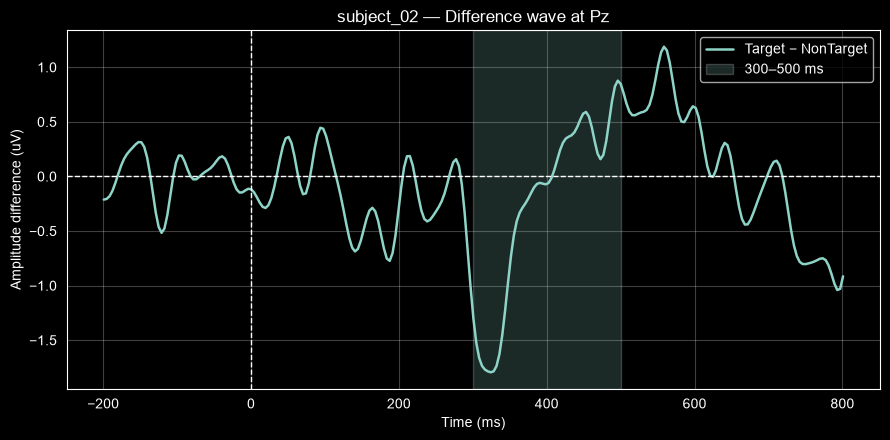

Saved: /Users/ziadelsisi/Hello World/Projects/Graduation Project /eeg-p300-recognition-assessment/figures/erp/unexpected_behavior_diagnostic/subject_02_difference_wave.png


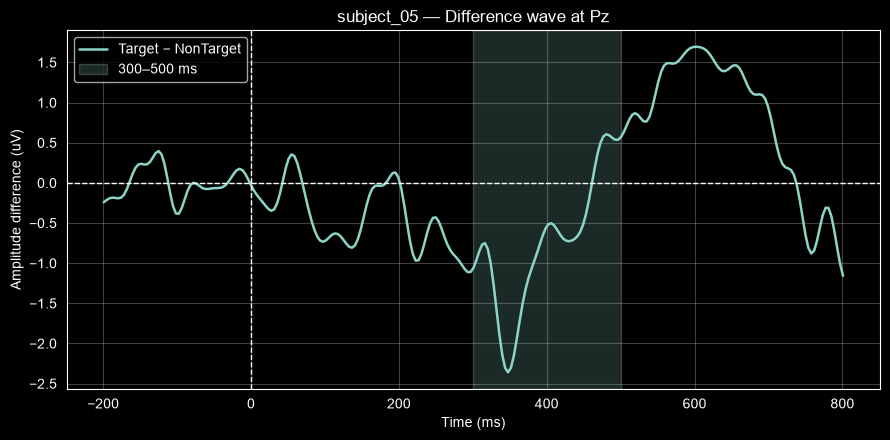

Saved: /Users/ziadelsisi/Hello World/Projects/Graduation Project /eeg-p300-recognition-assessment/figures/erp/unexpected_behavior_diagnostic/subject_05_difference_wave.png


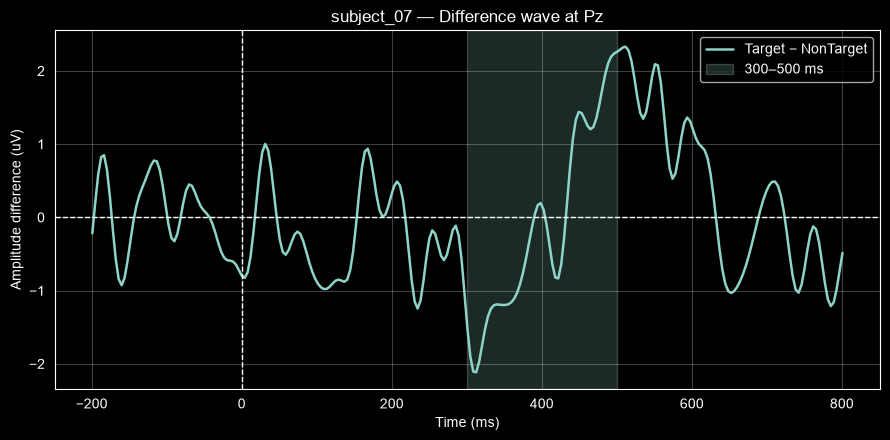

Saved: /Users/ziadelsisi/Hello World/Projects/Graduation Project /eeg-p300-recognition-assessment/figures/erp/unexpected_behavior_diagnostic/subject_07_difference_wave.png


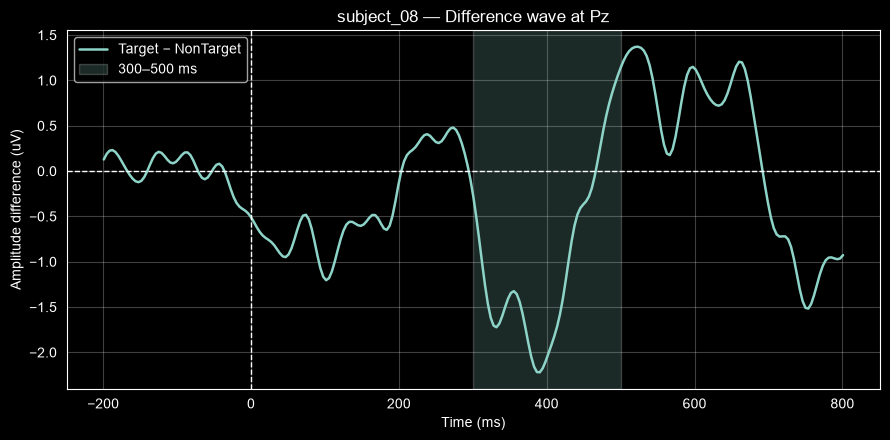

Saved: /Users/ziadelsisi/Hello World/Projects/Graduation Project /eeg-p300-recognition-assessment/figures/erp/unexpected_behavior_diagnostic/subject_08_difference_wave.png


In [12]:
for subject_label in unexpected_subjects:
    sid = int(subject_label.split("_")[1])
    target_evoked, nontarget_evoked, channel = evoked[sid]
    idx = target_evoked.ch_names.index(channel)

    times_ms = target_evoked.times * 1000
    diff_uv = (target_evoked.data[idx] - nontarget_evoked.data[idx]) * 1e6

    fig, ax = plt.subplots(figsize=(9, 4.5))
    ax.plot(times_ms, diff_uv, linewidth=1.8, label="Target − NonTarget")
    ax.axhline(0, linestyle="--", linewidth=1)
    ax.axvline(0, linestyle="--", linewidth=1)
    ax.axvspan(300, 500, alpha=0.2, label="300–500 ms")
    ax.set_title(f"{subject_label} — Difference wave at {channel}")
    ax.set_xlabel("Time (ms)")
    ax.set_ylabel("Amplitude difference (uV)")
    ax.legend()
    ax.grid(alpha=0.25)
    fig.tight_layout()

    path = FIGURES_DIR / f"{subject_label}_difference_wave.png"
    fig.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()
    print("Saved:", path)


## 12. Peak Detection Diagnostic

The existing Step 4 notebook searches for the positive peak **inside 300–500 ms**.
If a peak lands exactly at 500 ms, it may be a window-edge effect.

This cell uses a wider **250–600 ms diagnostic window**. It does not replace the Step 4
measurement; it tests whether the reported peak is being truncated by the analysis window.


In [13]:
peak_rows = []

for sid, (target_evoked, nontarget_evoked, channel) in evoked.items():
    for condition, e in [("Target", target_evoked), ("NonTarget", nontarget_evoked)]:
        lat_300, amp_300 = evoked_peak_uv(e, channel, P300_WINDOW)
        edge_300, _ = peak_at_boundary(e, channel, P300_WINDOW)

        lat_wide, amp_wide = evoked_peak_uv(e, channel, DIAGNOSTIC_PEAK_WINDOW)
        edge_wide, _ = peak_at_boundary(e, channel, DIAGNOSTIC_PEAK_WINDOW)

        peak_rows.append({
            "Subject": f"subject_{sid:02d}",
            "Condition": condition,
            "300-500 peak latency (ms)": lat_300,
            "300-500 peak amp (uV)": amp_300,
            "300-500 peak at boundary": edge_300,
            "250-600 peak latency (ms)": lat_wide,
            "250-600 peak amp (uV)": amp_wide,
            "250-600 peak at boundary": edge_wide,
        })

peak_df = pd.DataFrame(peak_rows)
display(peak_df[peak_df["Subject"].isin(unexpected_subjects)])


,Subject,Condition,300-500 peak latency (ms),300-500 peak amp (uV),300-500 peak at boundary,250-600 peak latency (ms),250-600 peak amp (uV),250-600 peak at boundary
2,subject_02,Target,500.00000,1.155037,True,503.90625,1.160302,False
3,subject_02,NonTarget,500.00000,0.307307,True,261.71875,0.640464,False
8,subject_05,Target,476.56250,0.349743,False,601.56250,1.544741,True
9,subject_05,NonTarget,375.00000,0.853058,False,375.00000,0.853058,False
12,subject_07,Target,500.00000,2.545175,True,507.81250,2.626540,False
13,subject_07,NonTarget,417.96875,0.595394,False,250.00000,0.794962,True
14,subject_08,Target,500.00000,0.736001,True,519.53125,1.528666,False
15,subject_08,NonTarget,378.90625,1.491105,False,378.90625,1.491105,False


## 13. Trial-Level Variability

Because an ERP is an average, a weak or reversed subject-level ERP can result from high
trial-to-trial variability.

We therefore inspect the distribution of each epoch's mean Pz amplitude in 300–500 ms.
Cohen's d and a Mann–Whitney p-value are descriptive diagnostics, not classifier metrics.


In [14]:
trial_rows = []

for sid, ep in subjects.items():
    target_values = epoch_means_uv(ep["Target"], "Pz", P300_WINDOW)
    nontarget_values = epoch_means_uv(ep["NonTarget"], "Pz", P300_WINDOW)

    try:
        p_value = float(
            mannwhitneyu(
                target_values,
                nontarget_values,
                alternative="two-sided"
            ).pvalue
        )
    except Exception:
        p_value = np.nan

    trial_rows.append({
        "Subject": f"subject_{sid:02d}",
        "Target n": len(target_values),
        "Target trial mean (uV)": np.mean(target_values),
        "Target trial SD (uV)": np.std(target_values, ddof=1),
        "NonTarget n": len(nontarget_values),
        "NonTarget trial mean (uV)": np.mean(nontarget_values),
        "NonTarget trial SD (uV)": np.std(nontarget_values, ddof=1),
        "Cohen d": cohens_d(target_values, nontarget_values),
        "Mann-Whitney p": p_value,
    })

trial_df = pd.DataFrame(trial_rows)
display(trial_df[trial_df["Subject"].isin(unexpected_subjects)])


,Subject,Target n,Target trial mean (uV),Target trial SD (uV),NonTarget n,NonTarget trial mean (uV),NonTarget trial SD (uV),Cohen d,Mann-Whitney p
1,subject_02,697,-0.264822,4.570038,3482,0.028036,4.387761,-0.066278,6.152649e-03
4,subject_05,699,-0.646273,3.754218,3497,0.127580,3.974629,-0.196469,2.819574e-06
6,subject_07,640,-0.099897,4.494073,3362,0.066632,4.052047,-0.040363,2.894180e-01
7,subject_08,700,-0.815356,3.134204,3500,0.170244,3.138390,-0.314116,6.925154e-14


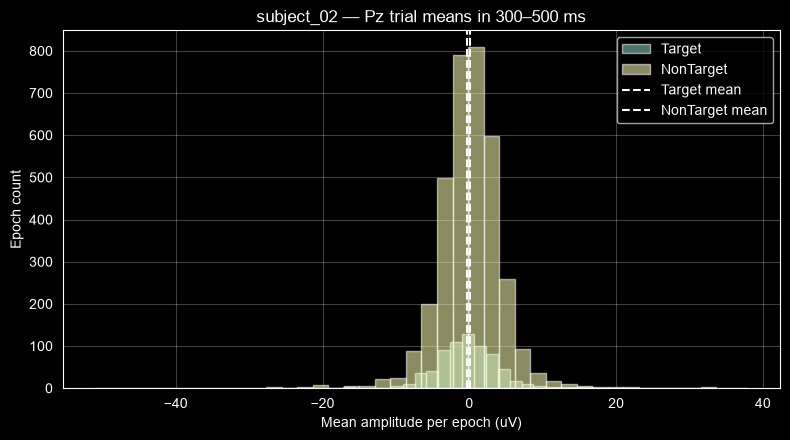

Saved: /Users/ziadelsisi/Hello World/Projects/Graduation Project /eeg-p300-recognition-assessment/figures/erp/unexpected_behavior_diagnostic/subject_02_trial_distribution.png


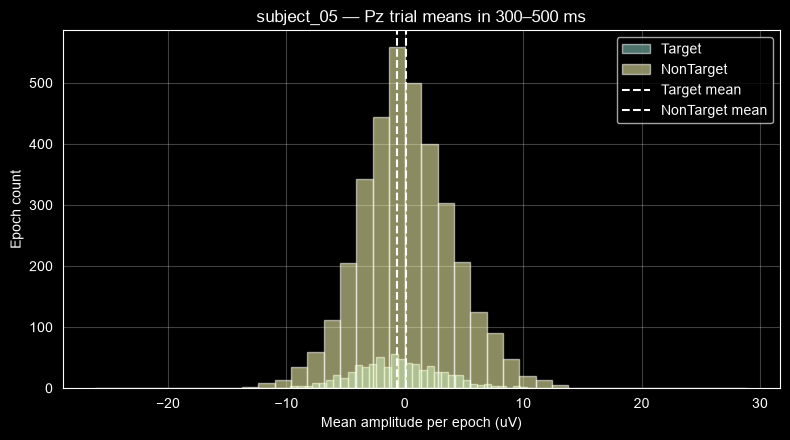

Saved: /Users/ziadelsisi/Hello World/Projects/Graduation Project /eeg-p300-recognition-assessment/figures/erp/unexpected_behavior_diagnostic/subject_05_trial_distribution.png


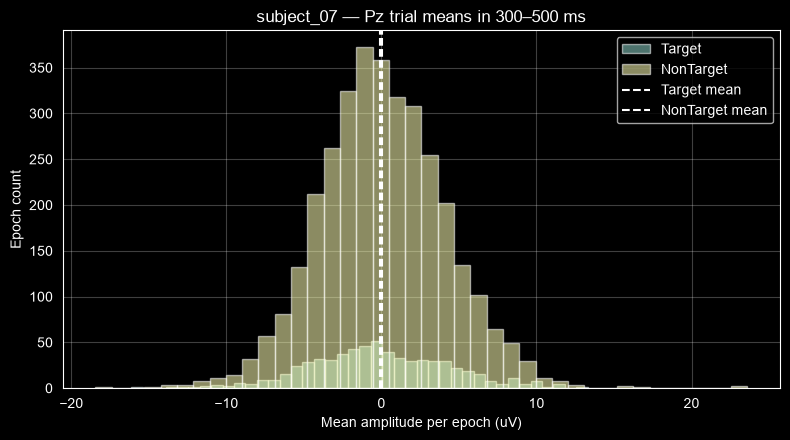

Saved: /Users/ziadelsisi/Hello World/Projects/Graduation Project /eeg-p300-recognition-assessment/figures/erp/unexpected_behavior_diagnostic/subject_07_trial_distribution.png


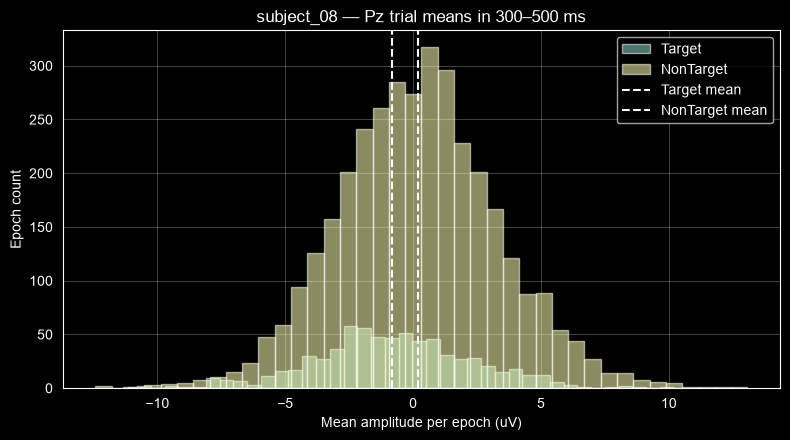

Saved: /Users/ziadelsisi/Hello World/Projects/Graduation Project /eeg-p300-recognition-assessment/figures/erp/unexpected_behavior_diagnostic/subject_08_trial_distribution.png


In [15]:
for subject_label in unexpected_subjects:
    sid = int(subject_label.split("_")[1])
    ep = subjects[sid]

    t = epoch_means_uv(ep["Target"], "Pz", P300_WINDOW)
    n = epoch_means_uv(ep["NonTarget"], "Pz", P300_WINDOW)

    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.hist(t, bins=40, alpha=0.55, label="Target")
    ax.hist(n, bins=40, alpha=0.55, label="NonTarget")
    ax.axvline(np.mean(t), linestyle="--", linewidth=1.5, label="Target mean")
    ax.axvline(np.mean(n), linestyle="--", linewidth=1.5, label="NonTarget mean")
    ax.set_title(f"{subject_label} — Pz trial means in 300–500 ms")
    ax.set_xlabel("Mean amplitude per epoch (uV)")
    ax.set_ylabel("Epoch count")
    ax.legend()
    ax.grid(alpha=0.25)
    fig.tight_layout()

    path = FIGURES_DIR / f"{subject_label}_trial_distribution.png"
    fig.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()
    print("Saved:", path)


## 14. Grand Average and Leave-One-Subject-Out Influence

This checks whether any individual subject strongly changes the group-level result.

A large leave-one-out change identifies an **influential subject**, not necessarily a faulty
subject.


In [16]:
target_evokeds = [v[0] for v in evoked.values()]
nontarget_evokeds = [v[1] for v in evoked.values()]

grand_target = mne.grand_average(target_evokeds, interpolate_bads=False, drop_bads=False)
grand_nontarget = mne.grand_average(nontarget_evokeds, interpolate_bads=False, drop_bads=False)

grand_channel = "Pz" if "Pz" in grand_target.ch_names else select_channel(grand_target.ch_names)

grand_target_mean = evoked_mean_uv(grand_target, grand_channel, P300_WINDOW)
grand_nontarget_mean = evoked_mean_uv(grand_nontarget, grand_channel, P300_WINDOW)
grand_diff = grand_target_mean - grand_nontarget_mean

print("Grand channel:", grand_channel)
print(f"Grand Target mean: {grand_target_mean:.4f} uV")
print(f"Grand NonTarget mean: {grand_nontarget_mean:.4f} uV")
print(f"Grand Target - NonTarget: {grand_diff:.4f} uV")


Identifying common channels ...
Identifying common channels ...
Grand channel: Pz
Grand Target mean: 0.0109 uV
Grand NonTarget mean: 0.0074 uV
Grand Target - NonTarget: 0.0035 uV


In [17]:
loo_rows = []

for excluded in sorted(evoked):
    remaining = [sid for sid in sorted(evoked) if sid != excluded]

    t = mne.grand_average(
        [evoked[sid][0] for sid in remaining],
        interpolate_bads=False,
        drop_bads=False
    )
    n = mne.grand_average(
        [evoked[sid][1] for sid in remaining],
        interpolate_bads=False,
        drop_bads=False
    )

    t_mean = evoked_mean_uv(t, grand_channel, P300_WINDOW)
    n_mean = evoked_mean_uv(n, grand_channel, P300_WINDOW)
    diff = t_mean - n_mean

    loo_rows.append({
        "Excluded subject": f"subject_{excluded:02d}",
        "LOO difference (uV)": diff,
        "Change from full grand difference (uV)": diff - grand_diff,
    })

loo_df = pd.DataFrame(loo_rows)
display(loo_df)


Identifying common channels ...
Identifying common channels ...
Identifying common channels ...
Identifying common channels ...
Identifying common channels ...
Identifying common channels ...
Identifying common channels ...
Identifying common channels ...
Identifying common channels ...
Identifying common channels ...
Identifying common channels ...
Identifying common channels ...
Identifying common channels ...
Identifying common channels ...
Identifying common channels ...
Identifying common channels ...


,Excluded subject,LOO difference (uV),Change from full grand difference (uV)
0,subject_01,-0.015860,-0.019320
1,subject_02,0.040697,0.037237
2,subject_03,-0.003297,-0.006757
3,subject_04,-0.086365,-0.089824
4,subject_05,0.109901,0.106441
5,subject_06,-0.177436,-0.180896
6,subject_07,0.018691,0.015231
7,subject_08,0.141350,0.137890


## 15. Visual Comparison of the Four Unexpected Subjects

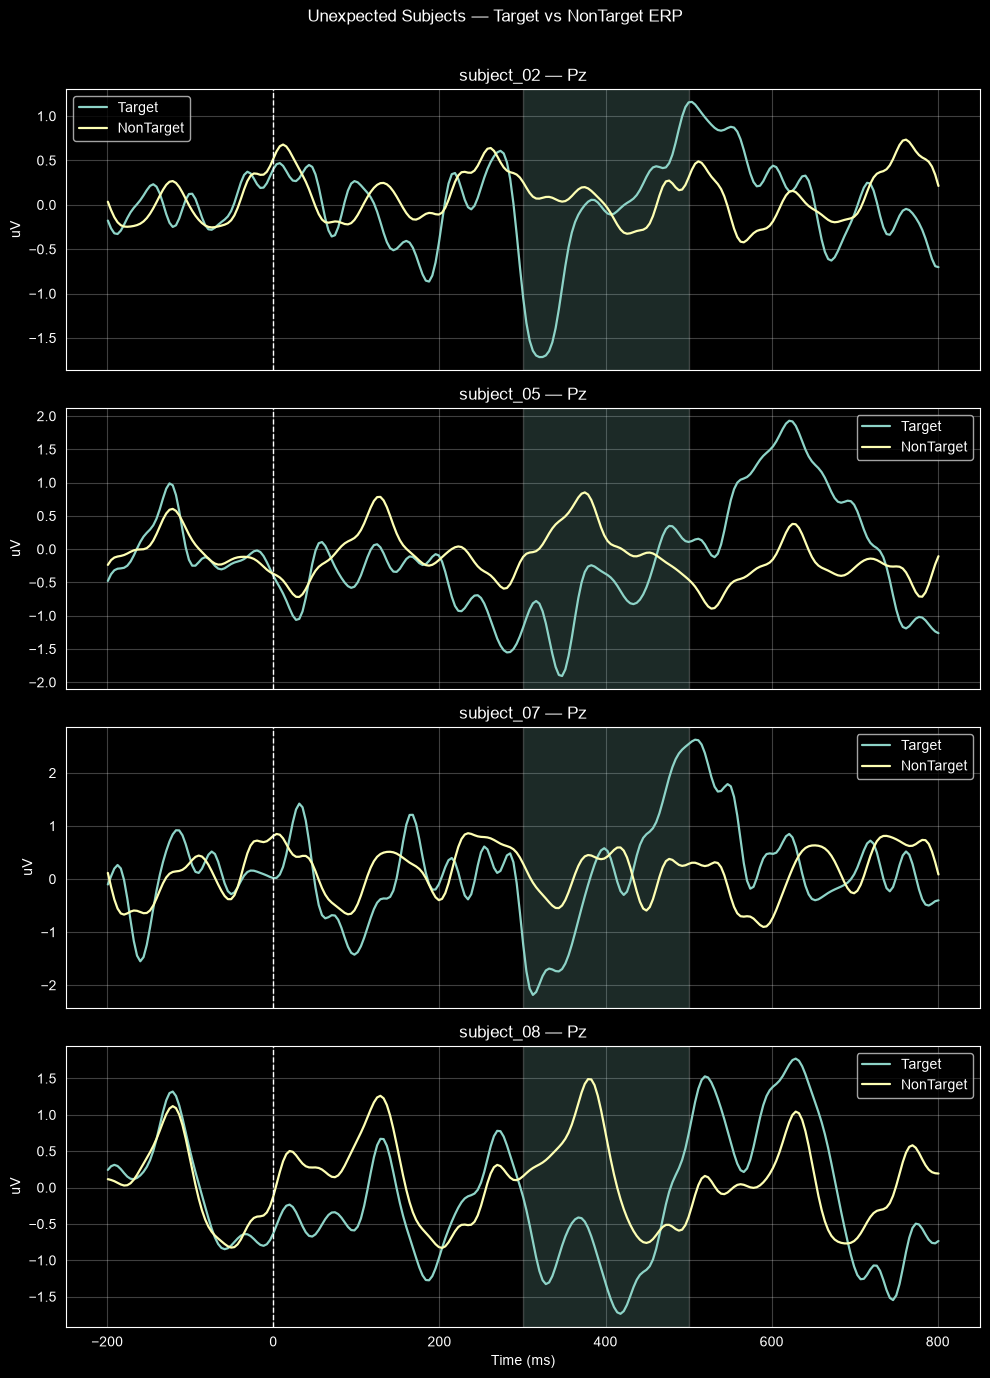

Saved: /Users/ziadelsisi/Hello World/Projects/Graduation Project /eeg-p300-recognition-assessment/figures/erp/unexpected_behavior_diagnostic/unexpected_subjects_erp_comparison.png


In [18]:
fig, axes = plt.subplots(
    len(unexpected_subjects), 1,
    figsize=(10, 3.4 * max(1, len(unexpected_subjects))),
    sharex=True
)

if len(unexpected_subjects) == 1:
    axes = [axes]

for ax, subject_label in zip(axes, unexpected_subjects):
    sid = int(subject_label.split("_")[1])
    target_evoked, nontarget_evoked, channel = evoked[sid]
    idx = target_evoked.ch_names.index(channel)
    times_ms = target_evoked.times * 1000

    ax.plot(times_ms, target_evoked.data[idx] * 1e6, label="Target", linewidth=1.6)
    ax.plot(times_ms, nontarget_evoked.data[idx] * 1e6, label="NonTarget", linewidth=1.6)
    ax.axvline(0, linestyle="--", linewidth=1)
    ax.axvspan(300, 500, alpha=0.2)

    ax.set_title(f"{subject_label} — {channel}")
    ax.set_ylabel("uV")
    ax.legend()
    ax.grid(alpha=0.25)

axes[-1].set_xlabel("Time (ms)")
fig.suptitle("Unexpected Subjects — Target vs NonTarget ERP Analysis", y=1.01)
fig.tight_layout()

path = FIGURES_DIR / "unexpected_subjects_erp_comparison.png"
fig.savefig(path, dpi=150, bbox_inches="tight")
plt.show()
print("Saved:", path)


## 16. Evidence-Based Diagnostic Summary

Interpret the findings conservatively:

- **Retention deviation**: a subject has a different retained-epoch count from the modal count.
- **Pz-specific/spatial finding**: Pz is negative while most channels are positive.
- **Broad spatial finding**: Pz is negative and most channels are also negative.
- **Peak-window finding**: the 300–500 ms peak is at/near a boundary.
- **High variability**: large trial-level spread can make the ERP average unstable.

These are clues, not proof of causation.


In [19]:
diagnostic_rows = []

for subject_label in unexpected_subjects:
    sid = int(subject_label.split("_")[1])
    er = erp_df[erp_df["Subject"] == subject_label].iloc[0]
    cs = channel_summary_df[channel_summary_df["Subject"] == subject_label].iloc[0]
    tr = trial_df[trial_df["Subject"] == subject_label].iloc[0]
    pk = peak_df[peak_df["Subject"] == subject_label]

    retention_changed = (
        er["Target epochs"] != modal_target
        or er["NonTarget epochs"] != modal_nontarget
    )

    positive_fraction = cs["Positive-channel fraction"]

    if er["Target-NonTarget mean (uV)"] < 0 and positive_fraction > 0.5:
        spatial = "Pz-specific/spatial inconsistency possible"
    elif er["Target-NonTarget mean (uV)"] < 0:
        spatial = "Broad multi-channel negative difference"
    else:
        spatial = "No negative Pz difference"

    edge = bool(pk["300-500 peak at boundary"].any())

    diagnostic_rows.append({
        "Subject": subject_label,
        "Retention differs from modal": retention_changed,
        "Pz difference (uV)": er["Target-NonTarget mean (uV)"],
        "Positive-channel fraction": positive_fraction,
        "Spatial finding": spatial,
        "Peak at 300-500 boundary": edge,
        "Cohen d": tr["Cohen d"],
        "Mann-Whitney p": tr["Mann-Whitney p"],
    })

diagnostic_df = pd.DataFrame(diagnostic_rows)
display(diagnostic_df)


,Subject,Retention differs from modal,Pz difference (uV),Positive-channel fraction,Spatial finding,Peak at 300-500 boundary,Cohen d,Mann-Whitney p
0,subject_02,True,-0.257198,0.25,Broad multi-channel negative difference,True,-0.066278,6.152649e-03
1,subject_05,True,-0.741627,0.00,Broad multi-channel negative difference,False,-0.196469,2.819574e-06
2,subject_07,True,-0.103156,0.75,Pz-specific/spatial inconsistency possible,True,-0.040363,2.894180e-01
3,subject_08,True,-0.961770,0.25,Broad multi-channel negative difference,True,-0.314116,6.925154e-14


## 17. Final Interpretation — What Actually Led to the Unexpected Behavior?

In [20]:
print("=" * 80)
print("FINAL DIAGNOSTIC REPORT")
print("=" * 80)

print(f"\nSubjects analyzed: {len(erp_df)}")
print(f"Expected: {len(expected_subjects)}")
print(f"Unexpected: {len(unexpected_subjects)}")

print("\nA. LABEL CHECK")
print("All loaded subjects contain Target and NonTarget labels:",
      bool(label_df["both labels present"].all()))
print(
    "Important: the stored event_id mapping does not by itself prove the semantic "
    "meaning of the numeric event IDs. Verify that against the BNCI2014-008 loader."
)

print("\nB. RETENTION CHECK")
retention_subjects = retention_df.loc[
    retention_df["Different from modal retention"], "Subject"
].tolist()
print("Subjects with non-modal retained counts:", retention_subjects)

print("\nC. SPATIAL CHECK")
for _, r in diagnostic_df.iterrows():
    print(
        f"{r['Subject']}: {r['Spatial finding']} | "
        f"positive channels={r['Positive-channel fraction']:.2f}"
    )

print("\nD. PEAK CHECK")
edge_subjects = diagnostic_df.loc[
    diagnostic_df["Peak at 300-500 boundary"], "Subject"
].tolist()
print("Unexpected subjects with boundary peak:", edge_subjects)

print("\nE. GROUP RESULT")
print(f"Grand Target - NonTarget mean at {grand_channel}: {grand_diff:.4f} uV")

print("\nF. SCIENTIFIC CONCLUSION")
print(
    "The four UNEXPECTED_PATTERN labels should not automatically be called pipeline errors."
)
print(
    "If the negative Target-NonTarget effect is present across several channels, "
    "the evidence points toward subject-level ERP Analysis variability rather than a Pz-only issue."
)
print(
    "If only Pz is negative while other channels are positive, the result is more "
    "consistent with spatial/channel variability."
)
print(
    "If a subject also has unusually low retained counts, increased rejection/retention "
    "imbalance is a possible contributor, but clean epochs alone cannot prove causation."
)
print(
    "If peaks occur at 500 ms, the previous peak measurement may be constrained by "
    "the 300–500 ms search window."
)
print(
    "A definitive artifact-rejection cause requires the original/raw data and rejection "
    "logs; this notebook intentionally does not invent such a cause."
)


FINAL DIAGNOSTIC REPORT

Subjects analyzed: 8
Expected: 4
Unexpected: 4

A. LABEL CHECK
All loaded subjects contain Target and NonTarget labels: True
Important: the stored event_id mapping does not by itself prove the semantic meaning of the numeric event IDs. Verify that against the BNCI2014-008 loader.

B. RETENTION CHECK
Subjects with non-modal retained counts: ['subject_01', 'subject_02', 'subject_03', 'subject_04', 'subject_05', 'subject_06', 'subject_07', 'subject_08']

C. SPATIAL CHECK
subject_02: Broad multi-channel negative difference | positive channels=0.25
subject_05: Broad multi-channel negative difference | positive channels=0.00
subject_07: Pz-specific/spatial inconsistency possible | positive channels=0.75
subject_08: Broad multi-channel negative difference | positive channels=0.25

D. PEAK CHECK
Unexpected subjects with boundary peak: ['subject_02', 'subject_07', 'subject_08']

E. GROUP RESULT
Grand Target - NonTarget mean at Pz: 0.0035 uV

F. SCIENTIFIC CONCLUSION
The

## 18. Save Diagnostic Tables

In [21]:
tables = {
    "01_label_and_counts.csv": label_df,
    "02_retention_analysis.csv": retention_df,
    "03_signal_timing_channel_consistency.csv": consistency_df,
    "04_baseline_analysis.csv": baseline_df,
    "05_subject_erp_measurements.csv": erp_df,
    "06_channel_level_differences.csv": channel_df,
    "07_channel_summary.csv": channel_summary_df,
    "08_peak_window_diagnostic.csv": peak_df,
    "09_trial_level_variability.csv": trial_df,
    "10_leave_one_subject_out.csv": loo_df,
    "11_final_diagnostic_summary.csv": diagnostic_df,
}

for filename, df in tables.items():
    df.to_csv(RESULTS_DIR / filename, index=False)

print("Saved diagnostic tables:")
for filename in tables:
    print(" -", RESULTS_DIR / filename)
print("\nSaved figures:")
for path in sorted(FIGURES_DIR.glob("*.png")):
    print(" -", path)


Saved diagnostic tables:
 - /Users/ziadelsisi/Hello World/Projects/Graduation Project /eeg-p300-recognition-assessment/results/erp/unexpected_behavior_diagnostic/01_label_and_counts.csv
 - /Users/ziadelsisi/Hello World/Projects/Graduation Project /eeg-p300-recognition-assessment/results/erp/unexpected_behavior_diagnostic/02_retention_analysis.csv
 - /Users/ziadelsisi/Hello World/Projects/Graduation Project /eeg-p300-recognition-assessment/results/erp/unexpected_behavior_diagnostic/03_signal_timing_channel_consistency.csv
 - /Users/ziadelsisi/Hello World/Projects/Graduation Project /eeg-p300-recognition-assessment/results/erp/unexpected_behavior_diagnostic/04_baseline_analysis.csv
 - /Users/ziadelsisi/Hello World/Projects/Graduation Project /eeg-p300-recognition-assessment/results/erp/unexpected_behavior_diagnostic/05_subject_erp_measurements.csv
 - /Users/ziadelsisi/Hello World/Projects/Graduation Project /eeg-p300-recognition-assessment/results/erp/unexpected_behavior_diagnostic/06_ch

# What to Report in the Project

Do **not** write "four subjects are wrong."

Instead, after running this notebook, report the actual evidence:

> "Four subjects did not satisfy the implemented P300 sanity check. Diagnostic analysis
> was performed across event labels, retained epoch counts, signal/timing consistency,
> baseline behavior, multiple EEG channels, peak-window effects, and trial-level
> variability. The results were used to distinguish subject-level ERP variability from
> possible preprocessing or data-quality issues. No preprocessing parameter was changed
> to force the expected pattern."

Then fill in the specific findings produced by the final diagnostic table.

This preserves the scientific integrity of Step 4.
